# Question 3: Metadata-Filtered RAG System for University Academic Information

In [1]:
# Create 20 academic documents

from pathlib import Path

DOCS_DIR = Path("university_academic_docs")
DOCS_DIR.mkdir(exist_ok=True)

academic_docs = {
    "01_IT_Lab_2026.txt": """
IT Laboratory Manual
Department: IT
Subject: Database Management Systems Lab
Document Type: Laboratory Manual
Academic Year: 2026

Students must complete SQL exercises involving table creation,
queries, joins, constraints, and aggregate functions. Students
must maintain a laboratory record and submit it for evaluation.
Practical assessments may include execution and explanation
of SQL programs. These are sample academic requirements.
""",
    "02_IT_Syllabus_2026.txt": """
IT Course Syllabus
Department: IT
Subject: Database Management Systems
Document Type: Syllabus
Academic Year: 2026

Units include relational database concepts, SQL, normalization,
transactions, indexing, and database security. Learning outcomes
include designing schemas and writing SQL queries.
This is a sample syllabus.
""",
    "03_IT_Exam_Rules_2026.txt": """
IT Examination Regulations
Department: IT
Subject: General Academic Regulations
Document Type: Regulation
Academic Year: 2026

Students must follow the examination instructions published
by the university. Identity verification and permitted materials
are governed by the official examination notice. This synthetic
example is not an official university regulation.
""",
    "04_IT_Notice_2026.txt": """
IT Academic Notice
Department: IT
Subject: Laboratory Submission
Document Type: Notice
Academic Year: 2026

Students should check the department notice board for the
published laboratory submission schedule. This is a sample notice.
""",
    "05_CSE_Lab_2026.txt": """
CSE Laboratory Manual
Department: CSE
Subject: Python Programming Lab
Document Type: Laboratory Manual
Academic Year: 2026

Sample exercises include variables, functions, file handling,
classes, exception handling, and basic data processing.
Students should document program output in their lab records.
""",
    "06_CSE_Syllabus_2026.txt": """
CSE Course Syllabus
Department: CSE
Subject: Data Structures
Document Type: Syllabus
Academic Year: 2026

Topics include arrays, linked lists, stacks, queues, trees,
graphs, searching, sorting, and algorithm complexity.
""",
    "07_CSE_Regulation_2026.txt": """
CSE Examination Regulation
Department: CSE
Subject: General Academic Regulations
Document Type: Regulation
Academic Year: 2026

Students should consult the applicable official regulations
for examination eligibility, assessment, and conduct.
This is a synthetic example.
""",
    "08_CSE_Notice_2026.txt": """
CSE Academic Notice
Department: CSE
Subject: Programming Lab
Document Type: Notice
Academic Year: 2026

Check the department's published notice for practical
assessment dates and laboratory submission information.
""",
    "09_AIML_Lab_2026.txt": """
AIML Laboratory Manual
Department: AIML
Subject: Machine Learning Lab
Document Type: Laboratory Manual
Academic Year: 2026

Sample laboratory exercises include data preprocessing,
train-test splitting, classification, regression, and evaluation.
Students should record experimental results and observations.
""",
    "10_AIML_Syllabus_2026.txt": """
AIML Course Syllabus
Department: AIML
Subject: Artificial Intelligence
Document Type: Syllabus
Academic Year: 2026

Topics include search algorithms, knowledge representation,
reasoning, machine learning fundamentals, and AI applications.
""",
    "11_AIML_Regulation_2026.txt": """
AIML Examination Regulation
Department: AIML
Subject: General Academic Regulations
Document Type: Regulation
Academic Year: 2026

Students must refer to current university rules for examinations.
This synthetic document does not replace official regulations.
""",
    "12_AIML_Notice_2026.txt": """
AIML Academic Notice
Department: AIML
Subject: Project Review
Document Type: Notice
Academic Year: 2026

Students should consult the published departmental schedule
for project review dates and submission instructions.
""",
    "13_IT_Lab_2025.txt": """
IT Laboratory Manual
Department: IT
Subject: Computer Networks Lab
Document Type: Laboratory Manual
Academic Year: 2025

Sample exercises include IP addressing, subnetting,
network configuration, and connectivity testing.
""",
    "14_IT_Syllabus_2025.txt": """
IT Course Syllabus
Department: IT
Subject: Operating Systems
Document Type: Syllabus
Academic Year: 2025

Topics include processes, threads, scheduling, memory
management, synchronization, and file systems.
""",
    "15_IT_Regulation_2025.txt": """
IT Examination Regulation
Department: IT
Subject: General Academic Regulations
Document Type: Regulation
Academic Year: 2025

This synthetic document illustrates an academic regulation
record for the 2025 academic year.
""",
    "16_CSE_Lab_2025.txt": """
CSE Laboratory Manual
Department: CSE
Subject: Data Structures Lab
Document Type: Laboratory Manual
Academic Year: 2025

Sample exercises include linked lists, stacks, queues,
tree traversals, sorting, and searching algorithms.
""",
    "17_CSE_Syllabus_2025.txt": """
CSE Course Syllabus
Department: CSE
Subject: Operating Systems
Document Type: Syllabus
Academic Year: 2025

Topics include operating-system architecture, processes,
CPU scheduling, memory management, and file systems.
""",
    "18_CSE_Regulation_2025.txt": """
CSE Examination Regulation
Department: CSE
Subject: General Academic Regulations
Document Type: Regulation
Academic Year: 2025

This synthetic record demonstrates the regulation document type.
Consult official university publications for actual rules.
""",
    "19_AIML_Lab_2025.txt": """
AIML Laboratory Manual
Department: AIML
Subject: Python for Data Science Lab
Document Type: Laboratory Manual
Academic Year: 2025

Sample exercises include NumPy arrays, data frames,
visualization, missing-value handling, and feature preparation.
""",
    "20_AIML_Syllabus_2025.txt": """
AIML Course Syllabus
Department: AIML
Subject: Data Science
Document Type: Syllabus
Academic Year: 2025

Topics include descriptive statistics, probability,
data cleaning, visualization, and introductory modeling.
"""
}

for filename, content in academic_docs.items():
    (DOCS_DIR / filename).write_text(
        content.strip(),
        encoding="utf-8"
    )

print("Documents created:", len(academic_docs))
print("Folder:", DOCS_DIR.resolve())


Documents created: 20
Folder: C:\Users\HP\university_academic_docs


In [2]:
# Load documents and assign metadata

from langchain_core.documents import Document

documents = []

for file_path in sorted(DOCS_DIR.glob("*.txt")):
    text = file_path.read_text(encoding="utf-8")

    parts = {}
    for line in text.splitlines():
        if ":" in line:
            key, value = line.split(":", 1)
            parts[key.strip().lower()] = value.strip()

    metadata = {
        "source": file_path.name,
        "department": parts.get("department", "Unknown"),
        "subject": parts.get("subject", "Unknown"),
        "document_type": parts.get("document type", "Unknown"),
        "academic_year": int(parts.get("academic year", "0"))
    }

    documents.append(
        Document(page_content=text, metadata=metadata)
    )

print("Loaded documents:", len(documents))
print("\nExample metadata:")
print(documents[0].metadata)


Loaded documents: 20

Example metadata:
{'source': '01_IT_Lab_2026.txt', 'department': 'IT', 'subject': 'Database Management Systems Lab', 'document_type': 'Laboratory Manual', 'academic_year': 2026}


In [3]:
# Split the documents and store them in ChromaDB

from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_ollama import OllamaEmbeddings
from langchain_chroma import Chroma
from pathlib import Path
import shutil

splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=75
)

chunks = splitter.split_documents(documents)

embeddings = OllamaEmbeddings(
    model="nomic-embed-text"
)

DB_PATH = Path("university_metadata_chroma")

# Rebuild only when intentionally refreshing the dataset.
if DB_PATH.exists():
    shutil.rmtree(DB_PATH)

vectorstore = Chroma.from_documents(
    documents=chunks,
    embedding=embeddings,
    collection_name="university_academic",
    persist_directory=str(DB_PATH)
)

print("Documents:", len(documents))
print("Chunks:", len(chunks))
print("ChromaDB collection created.")


Documents: 20
Chunks: 20
ChromaDB collection created.


In [4]:
# Test metadata-filtered retrieval

query = "What are the laboratory requirements?"

filters = {
    "$and": [
        {"department": {"$eq": "IT"}},
        {"academic_year": {"$eq": 2026}},
        {"document_type": {"$eq": "Laboratory Manual"}}
    ]
}

results = vectorstore.similarity_search(
    query,
    k=5,
    filter=filters
)

print("Retrieved chunks:", len(results))

for i, doc in enumerate(results, 1):
    print(f"\n--- Result {i} ---")
    print("Source:", doc.metadata["source"])
    print("Department:", doc.metadata["department"])
    print("Year:", doc.metadata["academic_year"])
    print("Type:", doc.metadata["document_type"])
    print("Evidence:", doc.page_content[:500])


Retrieved chunks: 1

--- Result 1 ---
Source: 01_IT_Lab_2026.txt
Department: IT
Year: 2026
Type: Laboratory Manual
Evidence: IT Laboratory Manual
Department: IT
Subject: Database Management Systems Lab
Document Type: Laboratory Manual
Academic Year: 2026

Students must complete SQL exercises involving table creation,
queries, joins, constraints, and aggregate functions. Students
must maintain a laboratory record and submit it for evaluation.
Practical assessments may include execution and explanation
of SQL programs. These are sample academic requirements.


In [5]:
# Generate a grounded answer

from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="llama3.2",
    temperature=0
)

def answer_filtered_query(query, filters, k=5):
    retrieved = vectorstore.similarity_search(
        query,
        k=k,
        filter=filters
    )

    if not retrieved:
        return {
            "answer": "No matching documents were found for the selected filters.",
            "sources": []
        }

    context = "\n\n".join(
        f"[S{i}] Source: {doc.metadata['source']}\n"
        f"{doc.page_content}"
        for i, doc in enumerate(retrieved, 1)
    )

    prompt = f"""
Answer using ONLY the evidence below.
Do not use outside knowledge.
Cite evidence using source labels such as [S1].
If the evidence is insufficient, say so explicitly.

Question: {query}

Evidence:
{context}

Answer:
"""

    response = llm.invoke(prompt)

    return {
        "answer": response.content,
        "sources": [
            {
                "source": doc.metadata["source"],
                "department": doc.metadata["department"],
                "subject": doc.metadata["subject"],
                "document_type": doc.metadata["document_type"],
                "academic_year": doc.metadata["academic_year"],
                "excerpt": doc.page_content
            }
            for doc in retrieved
        ]
    }

result = answer_filtered_query(
    "What are the laboratory requirements?",
    filters
)

print("ANSWER:\n", result["answer"])

for source in result["sources"]:
    print("\nSOURCE:", source["source"])
    print("EXCERPT:", source["excerpt"])


ANSWER:
 The laboratory requirements are:

* Students must complete SQL exercises involving table creation, queries, joins, constraints, and aggregate functions.
* Students must maintain a laboratory record and submit it for evaluation.
* Practical assessments may include execution and explanation of SQL programs.

Note: There is no explicit list of laboratory requirements, but rather a general outline of the types of activities that students must complete.

SOURCE: 01_IT_Lab_2026.txt
EXCERPT: IT Laboratory Manual
Department: IT
Subject: Database Management Systems Lab
Document Type: Laboratory Manual
Academic Year: 2026

Students must complete SQL exercises involving table creation,
queries, joins, constraints, and aggregate functions. Students
must maintain a laboratory record and submit it for evaluation.
Practical assessments may include execution and explanation
of SQL programs. These are sample academic requirements.


In [8]:
# Compare filtered and unfiltered retrieval
import pandas as pd
test_cases = [
    {
        "query": "What are the laboratory requirements?",
        "filters": {
            "$and": [
                {"department": {"$eq": "IT"}},
                {"academic_year": {"$eq": 2026}},
                {"document_type": {"$eq": "Laboratory Manual"}}
            ]
        }
    },
    {
        "query": "Explain the examination rules.",
        "filters": {"document_type": {"$eq": "Regulation"}}
    },
    {
        "query": "Find the syllabus topics.",
        "filters": {
            "$and": [
                {"department": {"$eq": "AIML"}},
                {"academic_year": {"$eq": 2025}},
                {"document_type": {"$eq": "Syllabus"}}
            ]
        }
    },
    {
        "query": "What programming exercises are required?",
        "filters": {
            "$and": [
                {"department": {"$eq": "CSE"}},
                {"academic_year": {"$eq": 2026}},
                {"document_type": {"$eq": "Laboratory Manual"}}
            ]
        }
    },
    {
        "query": "What does the notice say about submissions?",
        "filters": {
            "$and": [
                {"department": {"$eq": "IT"}},
                {"academic_year": {"$eq": 2026}},
                {"document_type": {"$eq": "Notice"}}
            ]
        }
    }
]

comparison_rows = []

for i, case in enumerate(test_cases, 1):
    unfiltered = vectorstore.similarity_search(
        case["query"], k=3
    )

    filtered = vectorstore.similarity_search(
        case["query"], k=3, filter=case["filters"]
    )

    comparison_rows.append({
        "Query_ID": i,
        "Query": case["query"],
        "Unfiltered_Count": len(unfiltered),
        "Filtered_Count": len(filtered),
        "Unfiltered_Sources": "; ".join(
            d.metadata["source"] for d in unfiltered
        ),
        "Filtered_Sources": "; ".join(
            d.metadata["source"] for d in filtered
        )
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

comparison_df.to_csv(
    "metadata_filter_comparison.csv",
    index=False
)


,Query_ID,Query,Unfiltered_Count,Filtered_Count,Unfiltered_Sources,Filtered_Sources
0,1,What are the laboratory requirements?,3,1,01_IT_Lab_2026.txt; 16_CSE_Lab_2025.txt; 09_AI...,01_IT_Lab_2026.txt
1,2,Explain the examination rules.,3,3,07_CSE_Regulation_2026.txt; 03_IT_Exam_Rules_2...,07_CSE_Regulation_2026.txt; 03_IT_Exam_Rules_2...
2,3,Find the syllabus topics.,3,1,14_IT_Syllabus_2025.txt; 17_CSE_Syllabus_2025....,20_AIML_Syllabus_2025.txt
3,4,What programming exercises are required?,3,1,05_CSE_Lab_2026.txt; 08_CSE_Notice_2026.txt; 1...,05_CSE_Lab_2026.txt
4,5,What does the notice say about submissions?,3,1,04_IT_Notice_2026.txt; 08_CSE_Notice_2026.txt;...,04_IT_Notice_2026.txt


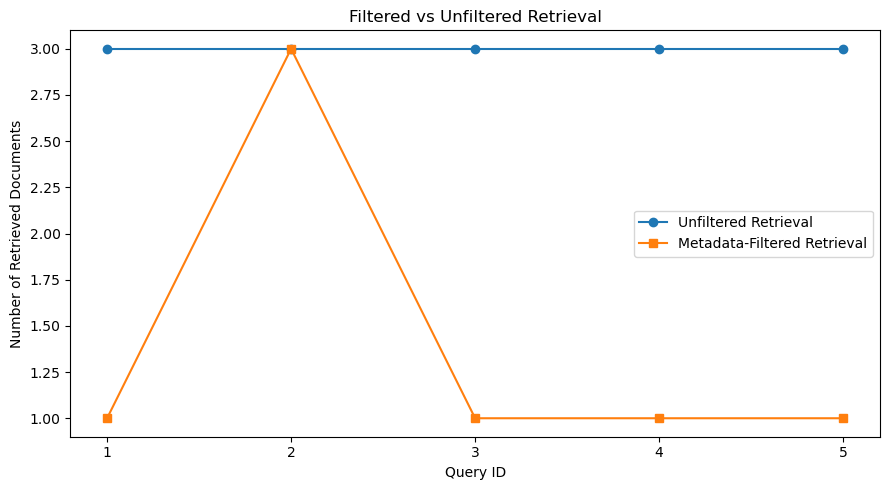

In [9]:
# Generate a comparison graph
import matplotlib.pyplot as plt

x = comparison_df["Query_ID"]

plt.figure(figsize=(9, 5))

plt.plot(
    x,
    comparison_df["Unfiltered_Count"],
    marker="o",
    label="Unfiltered Retrieval"
)

plt.plot(
    x,
    comparison_df["Filtered_Count"],
    marker="s",
    label="Metadata-Filtered Retrieval"
)

plt.xlabel("Query ID")
plt.ylabel("Number of Retrieved Documents")
plt.title("Filtered vs Unfiltered Retrieval")
plt.xticks(x)
plt.legend()
plt.tight_layout()

plt.savefig(
    "metadata_filter_comparison.png",
    dpi=150
)

plt.show()

In [10]:
# No matching documents test
no_match = vectorstore.similarity_search(
    "What are the scholarship rules?",
    k=5,
    filter={
        "$and": [
            {"department": {"$eq": "AIML"}},
            {"academic_year": {"$eq": 2030}},
            {"document_type": {"$eq": "Regulation"}}
        ]
    }
)

if not no_match:
    print("No matching documents found for the selected filters.")
else:
    print("Matching documents:", len(no_match))

No matching documents found for the selected filters.
